<a href="https://colab.research.google.com/github/shuob3344/MSSP6070/blob/main/WeeklyModules/Week09/PARTICIPATION_ACTIVITY_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [12]:
import requests
import bs4
import os
import pandas as pd

In [13]:
# Get cat photos from Flickr

url = 'https://www.flickr.com/services/feeds/photos_public.gne?tags=cat&format=rss_200'

res = requests.get(url)
res.raise_for_status()
print(res.status_code)
print(res.text[:500])

200
<?xml version="1.0" encoding="utf-8"?>
<rss version="2.0"
	    xmlns:media="http://search.yahoo.com/mrss/"
	    xmlns:dc="http://purl.org/dc/elements/1.1/"
	    xmlns:creativeCommons="http://cyber.law.harvard.edu/rss/creativeCommonsRssModule.html"
	    	    xmlns:flickr="urn:flickr:user" >
	<channel>


		<title>Recent Uploads tagged cat</title>
		<link>https://www.flickr.com/photos/tags/cat/</link>
 		<description></description>
		<pubDate>Thu, 29 Oct 2026 10:20:47 -0700</pubDate>
		<lastBuildDa


In [14]:
# Extract photo URLs from Flickr

soup = bs4.BeautifulSoup(res.content, 'xml')

images = soup.find_all('media:content')

image_urls = []

for image in images:
    image_url = image.get('url')
    image_type = image.get('type', '')

    if image_type.startswith('image/') and image_url:
        image_urls.append(image_url)

print('Number of photos:', len(image_urls))

for image_url in image_urls:
    print(image_url)

Number of photos: 19
https://live.staticflickr.com/65535/55619862258_d889d0122d_b.jpg
https://live.staticflickr.com/65535/55618486607_17381a5dfe_b.jpg
https://live.staticflickr.com/65535/55619484736_3f1435939e_b.jpg
https://live.staticflickr.com/65535/55619633948_e141fbc8d2_b.jpg
https://live.staticflickr.com/65535/55619484636_24658e5be7_b.jpg
https://live.staticflickr.com/65535/55619485081_b5c3014592_b.jpg
https://live.staticflickr.com/65535/55619484746_87ed4e319d_b.jpg
https://live.staticflickr.com/65535/55619634058_d8099b0762_b.jpg
https://live.staticflickr.com/65535/55619868735_8f22d63009_b.jpg
https://live.staticflickr.com/65535/55619590334_d38817b30d_b.jpg
https://live.staticflickr.com/65535/55619434883_801980193c_b.jpg
https://live.staticflickr.com/65535/55619643750_e5ea85d6e3_b.jpg
https://live.staticflickr.com/65535/55619435339_3dc9cf3c3f_b.jpg
https://live.staticflickr.com/65535/55619435479_3366df8cc4_b.jpg
https://live.staticflickr.com/65535/55618900011_cdd897b333_b.jpg
http

In [15]:
# Create a folder for photos
os.makedirs('cat_images', exist_ok=True)

# Download all photos
for i, image_url in enumerate(image_urls):

    res = requests.get(image_url)
    res.raise_for_status()

    filename = 'cat_images/cat_' + str(i + 1) + '.jpg'

    image_file = open(filename, 'wb')

    for chunk in res.iter_content(100000):
        image_file.write(chunk)

    image_file.close()

    print('Downloaded:', filename)

Downloaded: cat_images/cat_1.jpg
Downloaded: cat_images/cat_2.jpg
Downloaded: cat_images/cat_3.jpg
Downloaded: cat_images/cat_4.jpg
Downloaded: cat_images/cat_5.jpg
Downloaded: cat_images/cat_6.jpg
Downloaded: cat_images/cat_7.jpg
Downloaded: cat_images/cat_8.jpg
Downloaded: cat_images/cat_9.jpg
Downloaded: cat_images/cat_10.jpg
Downloaded: cat_images/cat_11.jpg
Downloaded: cat_images/cat_12.jpg
Downloaded: cat_images/cat_13.jpg
Downloaded: cat_images/cat_14.jpg
Downloaded: cat_images/cat_15.jpg
Downloaded: cat_images/cat_16.jpg
Downloaded: cat_images/cat_17.jpg
Downloaded: cat_images/cat_18.jpg
Downloaded: cat_images/cat_19.jpg


In [16]:
# Save photo information to CSV

photo_data = []

for i, image_url in enumerate(image_urls):
    photo_data.append({
        'Image Name': 'cat_' + str(i + 1) + '.jpg',
        'Category': 'cat',
        'Image URL': image_url
    })

df = pd.DataFrame(photo_data)

df.to_csv('cat_images.csv', index=False)

df

,Image Name,Category,Image URL
0,cat_1.jpg,cat,https://live.staticflickr.com/65535/5561986225...
1,cat_2.jpg,cat,https://live.staticflickr.com/65535/5561848660...
2,cat_3.jpg,cat,https://live.staticflickr.com/65535/5561948473...
3,cat_4.jpg,cat,https://live.staticflickr.com/65535/5561963394...
4,cat_5.jpg,cat,https://live.staticflickr.com/65535/5561948463...
5,cat_6.jpg,cat,https://live.staticflickr.com/65535/5561948508...
6,cat_7.jpg,cat,https://live.staticflickr.com/65535/5561948474...
7,cat_8.jpg,cat,https://live.staticflickr.com/65535/5561963405...
8,cat_9.jpg,cat,https://live.staticflickr.com/65535/5561986873...
9,cat_10.jpg,cat,https://live.staticflickr.com/65535/5561959033...


In [17]:
# Check downloaded images

files = os.listdir('cat_images')

print('Number of downloaded images:', len(files))
print('Number of CSV records:', len(df))

Number of downloaded images: 19
Number of CSV records: 19


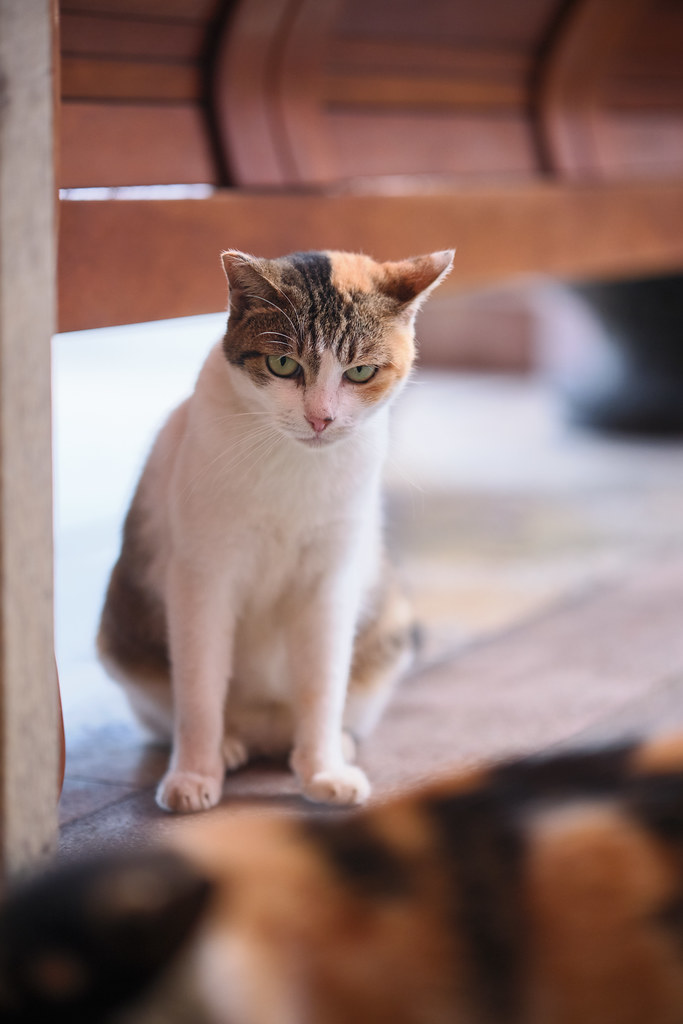

In [19]:
# Display a downloaded image

from IPython.display import Image, display

display(Image(filename='cat_images/cat_3.jpg'))